In [16]:
# 0. Imports et configuration GPU
import time, json, numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms, models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "(PAS de GPU !)")

def set_seed(seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
RESULTS = {}   # stocke les résultats de chaque modèle pour la comparaison finale

Device : cuda Tesla T4


In [17]:
# 1. Fonctions communes : données, évaluation, entraînement
def get_loaders(batch_size=128, size=28, channels=1, imagenet_norm=False, train_subset=None, test_subset=None):
    tfs = []
    if size != 28: tfs.append(transforms.Resize((size, size)))
    if channels == 3: tfs.append(transforms.Grayscale(num_output_channels=3))
    tfs.append(transforms.ToTensor())
    if imagenet_norm:
        tfs.append(transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)))
    else:
        tfs.append(transforms.Normalize((0.1307,), (0.3081,)))
    tf = transforms.Compose(tfs)
    train = datasets.MNIST("data", train=True, download=True, transform=tf)
    test = datasets.MNIST("data", train=False, download=True, transform=tf)
    if train_subset: train = Subset(train, range(train_subset))
    if test_subset: test = Subset(test, range(test_subset))
    kw = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    return (DataLoader(train, batch_size=batch_size, shuffle=True, **kw),
            DataLoader(test, batch_size=batch_size, shuffle=False, **kw))

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total, preds, gts = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); gts.append(y.cpu())
    preds, gts = torch.cat(preds).numpy(), torch.cat(gts).numpy()
    return total / len(gts), accuracy_score(gts, preds), f1_score(gts, preds, average="macro")

def fit(model, name, train_loader, test_loader, epochs=5, optimizer=None, scheduler=None, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    opt = optimizer or torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = dict(train_loss=[], test_loss=[], test_acc=[], test_f1=[])
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); opt.step()
            run += loss.item() * x.size(0)
        if scheduler: scheduler.step()
        tl = run / len(train_loader.dataset)
        vl, acc, f1 = evaluate(model, test_loader, criterion)
        hist["train_loss"].append(tl); hist["test_loss"].append(vl)
        hist["test_acc"].append(acc); hist["test_f1"].append(f1)
        print(f"[{name}] epoch {ep}/{epochs} | train_loss={tl:.4f} | test_loss={vl:.4f} | acc={acc:.4f} | f1={f1:.4f}")
    RESULTS[name] = dict(accuracy=hist["test_acc"][-1], f1=hist["test_f1"][-1], loss=hist["test_loss"][-1],
                         train_time_s=time.time() - t0, params=sum(p.numel() for p in model.parameters()), history=hist)
    print(f"Temps d'entraînement : {RESULTS[name]['train_time_s']:.1f} s")
    return model

Q1 : CNN classifier sur MNIST

In [18]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, kernel_size=3, stride=1, padding=1),
                                 nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))   # 1x28x28 -> 128x3x3
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 3 * 3, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(0.5), nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
train_loader, test_loader = get_loaders(batch_size=128)
cnn = CNN().to(device)
print(cnn)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.5)
cnn = fit(cnn, "CNN", train_loader, test_loader, epochs=8, optimizer=opt, scheduler=sched)

100%|██████████| 9.91M/9.91M [00:00<00:00, 130MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 44.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 137MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.8MB/s]


CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
   

Partie 1, Q2 : Faster R-CNN

In [20]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

CANVAS = 128
class DetMNIST(Dataset):
    def __init__(self, train=True, n=10000, seed=0):
        self.ds = datasets.MNIST("data", train=train, download=True)
        self.n = n
        self.pos = np.random.RandomState(seed).randint(0, CANVAS - 28, size=(n, 2))
    def __len__(self): return self.n
    def __getitem__(self, i):
        img, label = self.ds[i]
        arr = np.array(img, dtype=np.float32) / 255.0
        x0, y0 = self.pos[i]
        canvas = np.zeros((CANVAS, CANVAS), np.float32)
        canvas[y0:y0 + 28, x0:x0 + 28] = arr
        ys, xs = np.nonzero(arr > 0.1)
        box = [x0 + xs.min(), y0 + ys.min(), x0 + xs.max() + 1, y0 + ys.max() + 1]
        t = torch.from_numpy(canvas).unsqueeze(0).repeat(3, 1, 1)
        return t, dict(boxes=torch.tensor([box], dtype=torch.float32), labels=torch.tensor([label + 1]))

collate = lambda b: tuple(zip(*b))
N_TRAIN, N_TEST, EPOCHS_FRCNN = 10000, 2000, 3
det_train = DataLoader(DetMNIST(True, N_TRAIN), batch_size=16, shuffle=True, collate_fn=collate, num_workers=2)
det_test = DataLoader(DetMNIST(False, N_TEST, seed=1), batch_size=16, collate_fn=collate, num_workers=2)

frcnn = fasterrcnn_mobilenet_v3_large_fpn(weights=None, weights_backbone="DEFAULT",
                                          trainable_backbone_layers=3, min_size=CANVAS, max_size=CANVAS,
                                          box_score_thresh=0.0)
frcnn.roi_heads.box_predictor = FastRCNNPredictor(frcnn.roi_heads.box_predictor.cls_score.in_features, 11)
frcnn.to(device)

@torch.no_grad()
def eval_frcnn(model, loader):
    model.eval(); preds, gts = [], []
    for imgs, tg in loader:
        for o, t in zip(model([i.to(device) for i in imgs]), tg):
            preds.append(o["labels"][o["scores"].argmax()].item() - 1 if len(o["scores"]) else -1)
            gts.append(t["labels"].item() - 1)
    return accuracy_score(gts, preds), f1_score(gts, preds, average="macro")

params = [p for p in frcnn.parameters() if p.requires_grad]
BASE_LR, WARMUP = 0.003, 300
opt = torch.optim.SGD(params, lr=BASE_LR, momentum=0.9, weight_decay=5e-4)
it = 0
hist = dict(train_loss=[], test_loss=[], test_acc=[], test_f1=[]); t0 = time.time()
for ep in range(1, EPOCHS_FRCNN + 1):
    frcnn.train(); run = 0.0
    for imgs, tg in det_train:
        imgs = [i.to(device) for i in imgs]
        tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
        lr = BASE_LR * min(1.0, (it + 1) / WARMUP) * (0.1 if ep == EPOCHS_FRCNN else 1.0)  # warmup + decay
        for g in opt.param_groups: g['lr'] = lr
        it += 1
        loss = sum(frcnn(imgs, tg).values())      # somme des 4 pertes (RPN + ROI heads)
        if not torch.isfinite(loss):              # on ignore un batch instable au lieu de casser les poids
            opt.zero_grad(); continue
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(params, 10.0)   # evite l'explosion du gradient
        opt.step(); run += loss.item() * len(imgs)
    acc, f1 = eval_frcnn(frcnn, det_test)
    hist["train_loss"].append(run / N_TRAIN); hist["test_loss"].append(run / N_TRAIN)
    hist["test_acc"].append(acc); hist["test_f1"].append(f1)
    print(f"[Faster R-CNN] epoch {ep}/{EPOCHS_FRCNN} | loss={run / N_TRAIN:.4f} | acc={acc:.4f} | f1={f1:.4f}")
RESULTS["Faster R-CNN"] = dict(accuracy=hist["test_acc"][-1], f1=hist["test_f1"][-1], loss=hist["train_loss"][-1],
                               train_time_s=time.time() - t0, params=sum(p.numel() for p in frcnn.parameters()), history=hist)
print(f"Temps d'entraînement : {RESULTS['Faster R-CNN']['train_time_s']:.1f} s")

[Faster R-CNN] epoch 1/3 | loss=0.6302 | acc=0.5350 | f1=0.5087
[Faster R-CNN] epoch 2/3 | loss=0.9269 | acc=0.8485 | f1=0.8481
[Faster R-CNN] epoch 3/3 | loss=0.9239 | acc=0.8895 | f1=0.8890
Temps d'entraînement : 289.6 s


Q4 : Fine-tuning de VGG16 et AlexNet (pré-entraînés ImageNet)

In [21]:
def build_pretrained(name):
    m = models.vgg16(weights=models.VGG16_Weights.DEFAULT) if name == "VGG16" \
        else models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
    for p in m.features.parameters(): p.requires_grad = False      # gel du feature extractor
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 10)  # nouvelle tête 10 classes
    return m

set_seed()
tl_train, tl_test = get_loaders(batch_size=128, size=64, channels=3, imagenet_norm=True, train_subset=20000)
for name in ["AlexNet (fine-tuned)", "VGG16 (fine-tuned)"]:
    m = build_pretrained("VGG16" if "VGG" in name else "AlexNet").to(device)
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
    fit(m, name, tl_train, tl_test, epochs=3, optimizer=opt)
    del m; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:00<00:00, 252MB/s] 


[AlexNet (fine-tuned)] epoch 1/3 | train_loss=0.5307 | test_loss=0.2496 | acc=0.9162 | f1=0.9152
[AlexNet (fine-tuned)] epoch 2/3 | train_loss=0.2801 | test_loss=0.1951 | acc=0.9369 | f1=0.9359
[AlexNet (fine-tuned)] epoch 3/3 | train_loss=0.2299 | test_loss=0.1775 | acc=0.9411 | f1=0.9399
Temps d'entraînement : 27.0 s
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 222MB/s] 


[VGG16 (fine-tuned)] epoch 1/3 | train_loss=0.4255 | test_loss=0.1736 | acc=0.9445 | f1=0.9440
[VGG16 (fine-tuned)] epoch 2/3 | train_loss=0.1572 | test_loss=0.1209 | acc=0.9617 | f1=0.9615
[VGG16 (fine-tuned)] epoch 3/3 | train_loss=0.1218 | test_loss=0.1184 | acc=0.9615 | f1=0.9612
Temps d'entraînement : 84.1 s


Partie 2 : Vision Transformer (ViT) from scratch

In [22]:
def patchify(images, n_patches):
    n, c, h, w = images.shape
    ps = h // n_patches
    p = images.unfold(2, ps, ps).unfold(3, ps, ps)                       # n,c,P,P,ps,ps
    return p.permute(0, 2, 3, 1, 4, 5).reshape(n, n_patches ** 2, c * ps * ps)

def positional_embeddings(seq_len, d):
    pe = torch.ones(seq_len, d)
    for i in range(seq_len):
        for j in range(d):
            pe[i][j] = np.sin(i / 10000 ** (j / d)) if j % 2 == 0 else np.cos(i / 10000 ** ((j - 1) / d))
    return pe

class MSA(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        assert d % heads == 0
        self.d, self.h, self.dh = d, heads, d // heads
        self.qkv, self.out = nn.Linear(d, 3 * d), nn.Linear(d, d)
    def forward(self, x):
        n, s, _ = x.shape
        q, k, v = self.qkv(x).reshape(n, s, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1) / self.dh ** 0.5).softmax(-1)
        return self.out((att @ v).transpose(1, 2).reshape(n, s, self.d))

class Block(nn.Module):
    def __init__(self, d, heads, ratio=4):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.msa = MSA(d, heads)
        self.mlp = nn.Sequential(nn.Linear(d, ratio * d), nn.GELU(), nn.Linear(ratio * d, d))
    def forward(self, x):
        x = x + self.msa(self.n1(x))
        return x + self.mlp(self.n2(x))

class ViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, n_blocks=4, hidden_d=64, n_heads=4, out_d=10):
        super().__init__()
        c, h, w = chw
        self.n_patches = n_patches
        self.embed = nn.Linear(c * (h // n_patches) * (w // n_patches), hidden_d)
        self.cls = nn.Parameter(torch.rand(1, hidden_d))
        self.register_buffer("pos", positional_embeddings(n_patches ** 2 + 1, hidden_d))
        self.blocks = nn.ModuleList([Block(hidden_d, n_heads) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.LayerNorm(hidden_d), nn.Linear(hidden_d, out_d))
    def forward(self, x):
        t = self.embed(patchify(x, self.n_patches))
        t = torch.stack([torch.vstack((self.cls, tok)) for tok in t]) + self.pos
        for b in self.blocks: t = b(t)
        return self.head(t[:, 0])

set_seed()
train_loader, test_loader = get_loaders(batch_size=128)
vit = ViT().to(device)
opt = torch.optim.Adam(vit.parameters(), lr=5e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10)
vit = fit(vit, "ViT", train_loader, test_loader, epochs=10, optimizer=opt, scheduler=sched)

[ViT] epoch 1/10 | train_loss=0.7723 | test_loss=0.2586 | acc=0.9188 | f1=0.9166
[ViT] epoch 2/10 | train_loss=0.2107 | test_loss=0.1477 | acc=0.9531 | f1=0.9526
[ViT] epoch 3/10 | train_loss=0.1350 | test_loss=0.1214 | acc=0.9625 | f1=0.9621
[ViT] epoch 4/10 | train_loss=0.1061 | test_loss=0.0933 | acc=0.9691 | f1=0.9687
[ViT] epoch 5/10 | train_loss=0.0809 | test_loss=0.0885 | acc=0.9715 | f1=0.9714
[ViT] epoch 6/10 | train_loss=0.0649 | test_loss=0.0683 | acc=0.9790 | f1=0.9789
[ViT] epoch 7/10 | train_loss=0.0477 | test_loss=0.0511 | acc=0.9824 | f1=0.9821
[ViT] epoch 8/10 | train_loss=0.0317 | test_loss=0.0468 | acc=0.9851 | f1=0.9850
[ViT] epoch 9/10 | train_loss=0.0206 | test_loss=0.0428 | acc=0.9860 | f1=0.9859
[ViT] epoch 10/10 | train_loss=0.0143 | test_loss=0.0384 | acc=0.9870 | f1=0.9869
Temps d'entraînement : 118.8 s


Comparaison finale : Accuracy, F1, Loss, temps d'entraînement

,Accuracy,F1 (macro),Loss,Temps (s),Paramètres
CNN,0.9939,0.9939,0.0195,76.8235,390858.0
Faster R-CNN,0.8895,0.8890,0.9239,289.5855,18976354.0
AlexNet (fine-tuned),0.9411,0.9399,0.1775,27.0449,57044810.0
VGG16 (fine-tuned),0.9615,0.9612,0.1184,84.0572,134301514.0
ViT,0.9870,0.9869,0.0384,118.7553,201866.0


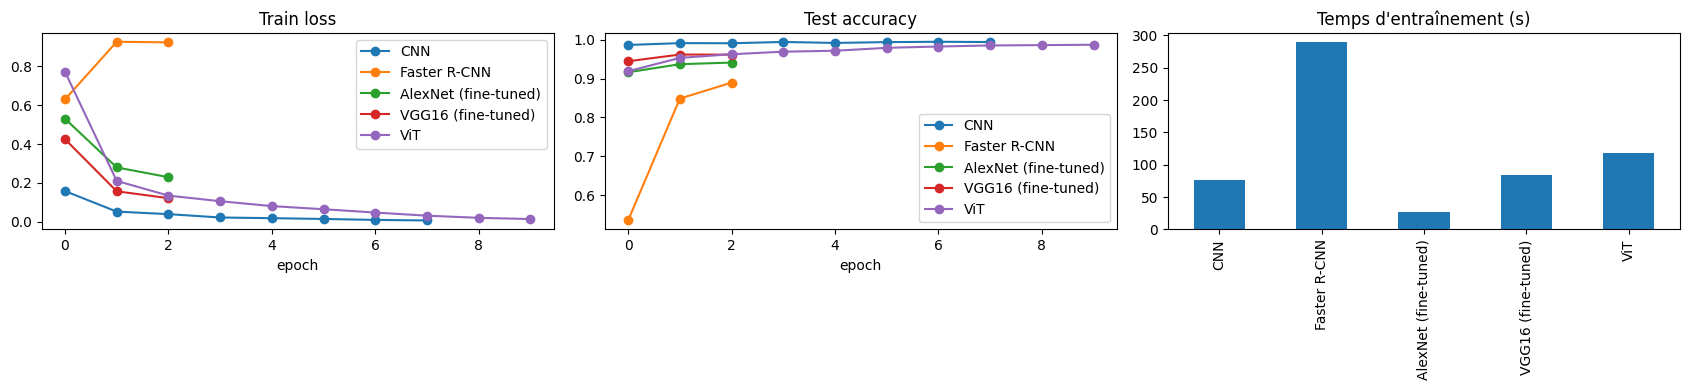

In [23]:
import pandas as pd
df = pd.DataFrame({k: {"Accuracy": v["accuracy"], "F1 (macro)": v["f1"], "Loss": v["loss"],
                       "Temps (s)": v["train_time_s"], "Paramètres": v["params"]} for k, v in RESULTS.items()}).T
display(df.round(4))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, v in RESULTS.items():
    ax[0].plot(v["history"]["train_loss"], marker="o", label=k)
    ax[1].plot(v["history"]["test_acc"], marker="o", label=k)
ax[0].set_title("Train loss"); ax[1].set_title("Test accuracy")
df["Temps (s)"].plot.bar(ax=ax[2], title="Temps d'entraînement (s)")
for a in ax[:2]: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()